In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset

from os import path, listdir
from PIL import Image, ImageDraw

import yaml

In [2]:
DatasetRoot = "../Datasets/GTSDB/"

In [3]:
class DS(Dataset):
    def __init__(self, root, split, transform=None):
        self.root = root
        self.transform = transform
        self.imgs = []
        self.labels = []
        self.labelNames = []

        with open(path.join(root, "data.yaml"), 'r') as f:
            data = yaml.load(f, Loader=yaml.SafeLoader)

        imFolder = data[split]
        lFolder = imFolder.replace("images", "labels")
        
        nameList = data.get("names")
        for i in nameList:
            self.labelNames.append(nameList.get(i))
        
        # load all image files, sorting them to ensure that they are aligned
        for imName in list(sorted(listdir(path.join(root, imFolder)))):
            im = Image.open(path.join(root, imFolder, imName))
            imLabels = []
            with open(path.join(root, lFolder, imName.replace(".jpg", ".txt")), 'r') as file:
                for line in file:
                    l, x, y, w, h = line.strip().split(" ")
                    t = (int(l), float(x), float(y), float(w), float(h))
                    imLabels.append(t)

            self.imgs.append(im)
            self.labels.append(imLabels)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        sample = self.imgs[idx]
        label = self.labels[idx]
        
        if self.transform:
            sample = self.transform(sample)

        return sample, label

    def __len__(self):
        return len(self.imgs)

In [4]:
Data = DS(DatasetRoot, "train")

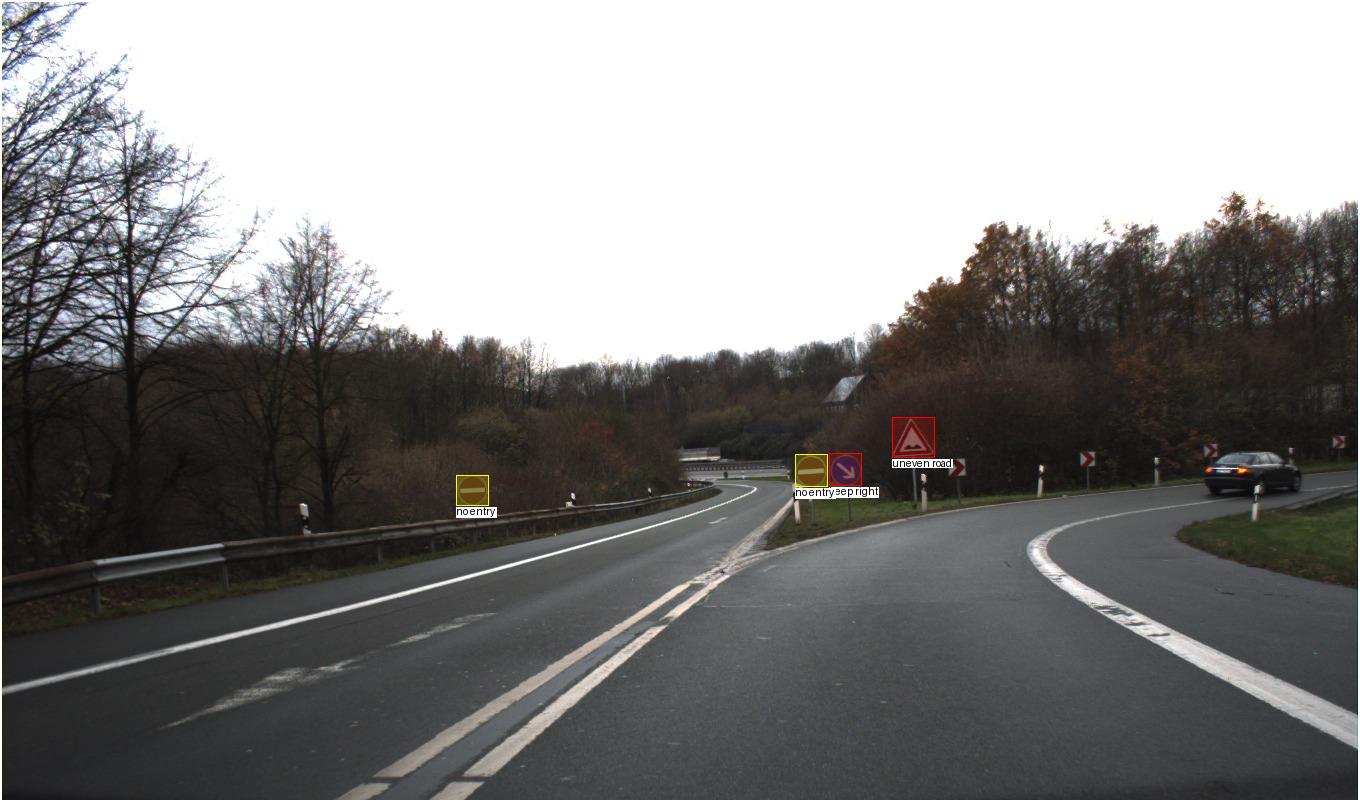

In [9]:
colors = [
    [255, 0, 0],
    [255, 0, 0],
    [255, 0, 0],
    [255, 255, 0],
    [0, 255, 255],
    [255, 0, 255],
]

def labelImage(Image, labels):
    copy = Image.copy()
    drawer = ImageDraw.Draw(copy, "RGBA")

    for l in labels:
        x, y, w, h = int(l[1] * Image.width), int(l[2] * Image.height), int(l[3] * Image.width / 2), int(l[4] * Image.height / 2)
        x1, y1 = x - w, y - h
        x2, y2 = x + w, y + h

        color = colors[l[0] % len(colors)]

        textPos = (x - w, y + h)
        textBox = drawer.textbbox(textPos, Data.labelNames[l[0]])
        drawer.rectangle(textBox, fill="white")
        drawer.text(textPos, Data.labelNames[l[0]], fill="black")
        drawer.rectangle((x1, y1, x2, y2), fill=tuple(color+[50]), outline=tuple(color+[255]), width=1)
    return copy

image = 1
im = labelImage(Data[image][0], Data[image][1])
display(im)

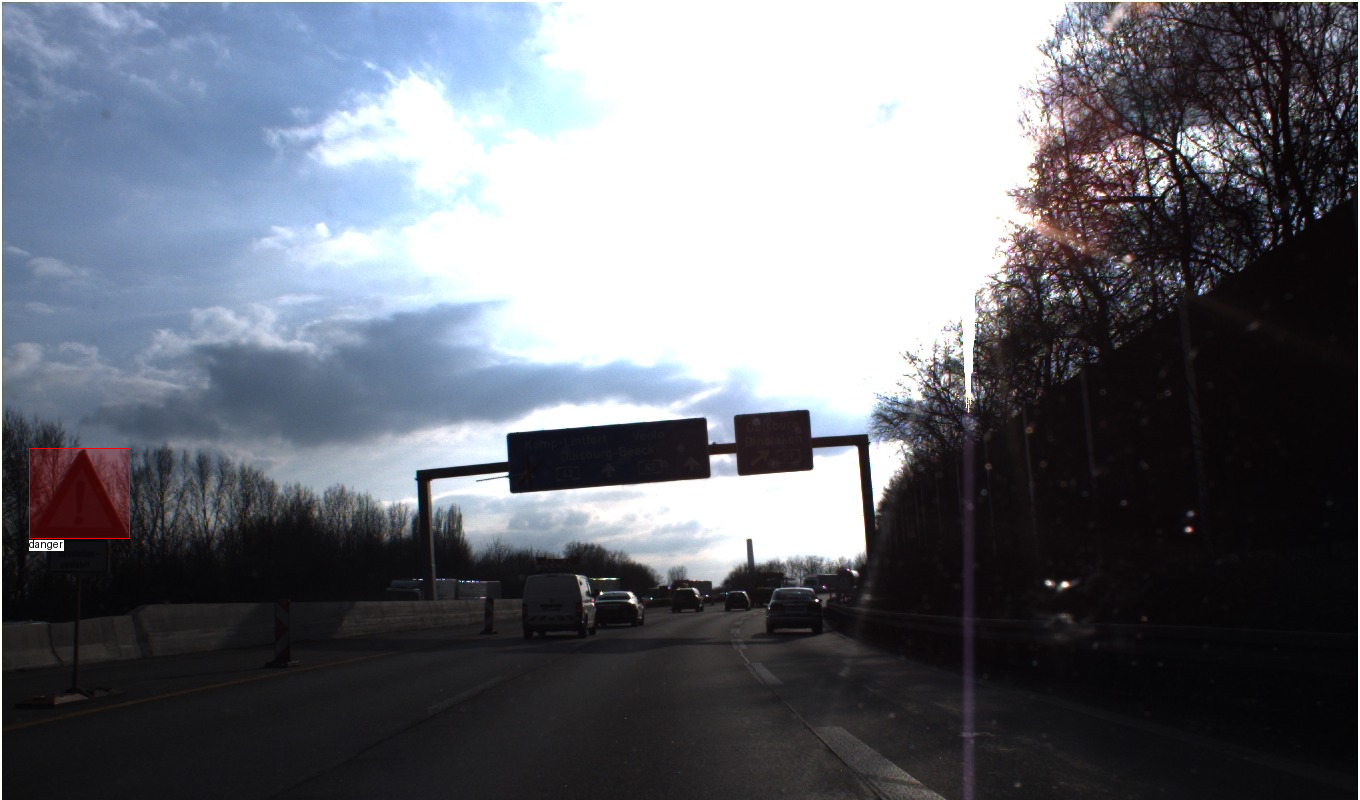

In [6]:
import random as r
for i in range(1):
    ID = r.randrange(0, len(Data))
    im = labelImage(Data[ID][0], Data[ID][1])
    display(im)